# 02 · Can a model tell Pluribus from human pros?

**Pluribus** is the poker AI from Carnegie Mellon and Facebook AI that beat elite professionals at 6-max No-Limit Hold'em (Brown & Sandholm, *Science*, 2019). It learned by playing trillions of hands against itself, so its play is the closest thing we have to "solver-like" 6-max poker.

The researchers published all **10,000 hands** of the experiment where Pluribus sat with five human pros. That gives us something our PokerStars data lacks: **labels**. Every decision is known to be made either by the bot or by a human.

**Goal:** train a supervised classifier that looks at a single decision (situation + what the player did) and predicts *bot or human*. If that works, the same model can later score PokerStars players on how bot-like or solver-like they play (notebook 03).

**Plan:**
1. Load the decisions and see how Pluribus differs from the pros.
2. Set up a fair test.
3. Train a simple baseline and a stronger model, and compare them.
4. Go from single decisions to whole players: how many decisions does it take to spot the bot?
5. Check what the model actually learned.

The data comes from [uoftcprg/phh-dataset](https://github.com/uoftcprg/phh-dataset) (MIT licence). `scripts/build_pluribus_decisions.py` replays every hand and writes one row per decision. It only uses **public information** (no hole cards), because most hole cards are hidden in our PokerStars data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from build_pluribus_decisions import DEFAULT_OUTPUT, build_decisions  # noqa: E402

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
RNG = 42

## 1. The decisions

In [2]:
if DEFAULT_OUTPUT.exists():
    d = pd.read_parquet(DEFAULT_OUTPUT)
else:
    d = build_decisions()
    d.to_parquet(DEFAULT_OUTPUT, index=False)

print(f"{len(d):,} decisions in {d.hand.nunique():,} hands over {d.session.nunique()} sessions")
print(f"Pluribus made {d.is_pluribus.mean():.1%} of the decisions")
d.head(8)

91,356 decisions in 10,000 hands over 92 sessions
Pluribus made 16.6% of the decisions


,session,hand,player,is_pluribus,street,position,players_left,raises_before,actions_before,facing_bet,pot_bb,to_call_bb,pot_odds,spr,in_position,was_preflop_aggressor,decision,size_pot,all_in
0,100,100/0,MrWhite,False,preflop,LJ,6,1,0,True,1.5,1.0,0.400000,66.666667,False,False,fold,0.000000,False
1,100,100/0,MrPink,False,preflop,HJ,5,1,1,True,1.5,1.0,0.400000,66.666667,False,False,raise,1.400000,False
2,100,100/0,MrBrown,False,preflop,CO,5,2,2,True,3.6,2.1,0.368421,27.777778,False,False,fold,0.000000,False
3,100,100/0,Pluribus,True,preflop,BTN,4,2,3,True,3.6,2.1,0.368421,27.777778,False,False,fold,0.000000,False
4,100,100/0,MrBlue,False,preflop,SB,3,2,4,True,3.6,1.6,0.307692,27.638889,False,False,call,0.444444,False
5,100,100/0,MrBlonde,False,preflop,BB,3,2,5,True,5.2,1.1,0.174603,19.038462,False,False,fold,0.000000,False
6,100,100/0,MrBlue,False,flop,SB,2,0,0,False,5.2,0.0,0.000000,18.826923,False,False,check,0.000000,False
7,100,100/0,MrPink,False,flop,HJ,2,0,1,False,5.2,0.0,0.000000,18.826923,True,True,check,0.000000,False


Each row is one decision. The most important columns:

| Column | Meaning |
|---|---|
| `street`, `position` | When and where the player acts |
| `players_left` | Players still in the hand |
| `raises_before` | Bets/raises already made on this street (preflop the big blind counts as one) |
| `facing_bet`, `pot_odds` | Whether the player must call, and the price of calling |
| `pot_bb`, `spr` | Pot size in big blinds, and stack-to-pot ratio (how deep the stacks are relative to the pot) |
| `in_position` | Acts last after the flop |
| `was_preflop_aggressor` | Made the last raise before the flop |
| `decision`, `size_pot` | What the player did, and the bet size as a share of the pot |

The human pros appear under pseudonyms (MrBlue, Bill, Eddie, …). A **session** is one table on one day; there are 92.

### How does Pluribus play differently?

First some familiar stats, computed the same way for Pluribus and for the pros as a group.

In [3]:
def style_stats(g: pd.DataFrame) -> pd.Series:
    pre = g[g.street == "preflop"]
    per_hand = pre.groupby(["hand", "player"]).decision.agg(lambda s: set(s))
    flop = g[g.street == "flop"]
    cbet_spots = flop[flop.was_preflop_aggressor & ~flop.facing_bet]
    facing_flop_bet = flop[flop.facing_bet]
    three_bet_spots = pre[pre.raises_before == 2]
    bets = g[g.decision.isin(["bet", "raise"]) & (g.street != "preflop")]
    return pd.Series({
        "VPIP %": 100 * per_hand.apply(lambda s: bool(s & {"call", "raise"})).mean(),
        "PFR %": 100 * per_hand.apply(lambda s: "raise" in s).mean(),
        "3-bet %": 100 * (three_bet_spots.decision == "raise").mean(),
        "Flop c-bet %": 100 * (cbet_spots.decision == "bet").mean(),
        "Fold to flop bet %": 100 * (facing_flop_bet.decision == "fold").mean(),
        "Raise vs flop bet %": 100 * (facing_flop_bet.decision == "raise").mean(),
        "Postflop overbets %": 100 * (bets.size_pot > 1.05).mean(),
        "All-in decisions %": 100 * g.all_in.mean(),
    })

style = d.groupby(d.is_pluribus.map({True: "Pluribus", False: "Human pros"})).apply(style_stats).T.round(1)
style

is_pluribus,Human pros,Pluribus
VPIP %,26.8,26.9
PFR %,17.8,18.0
3-bet %,7.9,7.3
Flop c-bet %,51.9,53.7
Fold to flop bet %,46.7,45.3
Raise vs flop bet %,8.8,9.8
Postflop overbets %,12.4,15.1
All-in decisions %,0.6,0.4


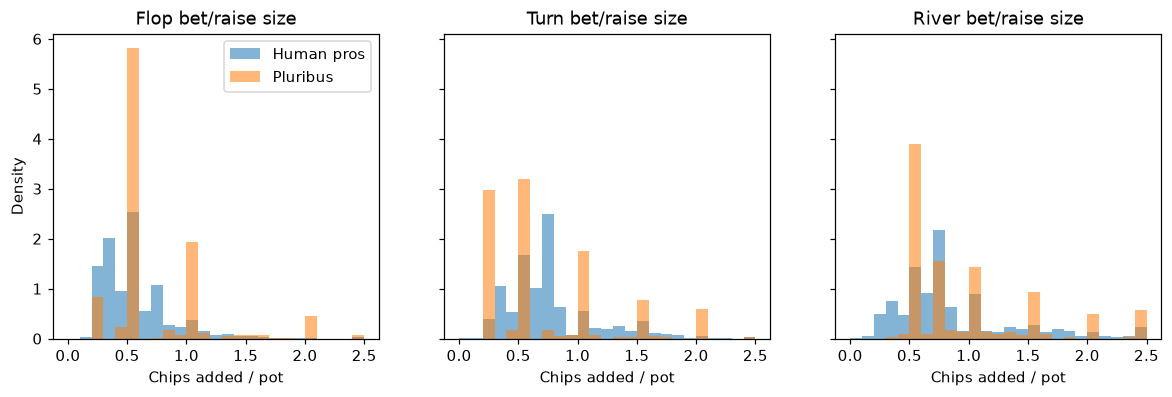

In [4]:
bets = d[d.decision.isin(["bet", "raise"]) & (d.street != "preflop")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
bins = np.linspace(0, 2.5, 26)
for ax, street in zip(axes, ["flop", "turn", "river"]):
    for label, g in bets[bets.street == street].groupby("is_pluribus"):
        ax.hist(g.size_pot.clip(upper=2.5), bins=bins, density=True, alpha=0.55,
                label="Pluribus" if label else "Human pros")
    ax.set(title=f"{street.title()} bet/raise size", xlabel="Chips added / pot")
axes[0].set_ylabel("Density")
axes[0].legend()
plt.show()

**On the familiar stats, Pluribus is almost indistinguishable from the pros**: the same VPIP and PFR, with small differences in 3-bet, c-bet and overbet frequency. A stats-based detector (like notebook 01) would never flag it.

**Bet sizes are a different story.** Pluribus only bets a few fixed sizes: ¼, ½, 1×, 1.5× and 2× the pot. That's because it was trained with a limited menu of bet sizes to keep the problem small enough. The humans' sizes are spread out. This is a real bot fingerprint, but a risky one: PokerStars players who use the preset bet buttons (½ pot, pot, …) also bet fixed sizes. We'll test in section 5 whether the model relies on it.

## 2. A fair test

The model must be tested on hands it has never seen. A random split of rows would put decisions from the same hand and session into both training and testing, and the result would look better than it really is. So we **split by session**: whole sessions are held out.

We use **5-fold cross-validation by session** (`GroupKFold`): the sessions are split into 5 groups, the model is trained on 4 groups and tested on the 5th, five times over. Every decision then gets a prediction from a model that never saw its session.

**Which score?** Only about 1 in 6 decisions is Pluribus's. A model that always says "human" is right 83% of the time and is useless, so accuracy is misleading here. We use:
- **ROC-AUC:** the chance that a random bot decision gets a higher bot score than a random human decision. 0.5 = guessing, 1.0 = perfect.
- **Average precision (AP):** how clean the top of the ranking is. Guessing gives the bot share, ≈ 0.17.

In [5]:
FEATURES_NUM = ["players_left", "raises_before", "actions_before", "pot_bb", "to_call_bb",
                "pot_odds", "spr", "size_pot"]
FEATURES_BOOL = ["facing_bet", "in_position", "was_preflop_aggressor", "all_in"]
FEATURES_CAT = ["street", "position", "decision"]

def make_X(frame: pd.DataFrame, num=FEATURES_NUM) -> pd.DataFrame:
    return pd.get_dummies(frame[num + FEATURES_BOOL + FEATURES_CAT], columns=FEATURES_CAT).astype(float)

X = make_X(d)
y = d.is_pluribus.to_numpy()
groups = d.session.to_numpy()
cv = GroupKFold(n_splits=5)
print(f"{X.shape[1]} feature columns after one-hot encoding")

27 feature columns after one-hot encoding


## 3. Models

1. **Always "human"** (a dummy model): the floor every real model must beat.
2. **Logistic regression:** a simple, interpretable baseline. It can only learn straight-line relationships ("more of X → more bot-like").
3. **Gradient-boosted trees** (`HistGradientBoostingClassifier`): builds many small decision trees, each fixing the previous ones' mistakes. It can learn combinations, such as "a small bet *on the river* *when in position*", which is what poker strategy is made of.

In [6]:
models = {
    "Always human": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=RNG),
}
scores = {}
results = []
for name, model in models.items():
    p = cross_val_predict(model, X, y, groups=groups, cv=cv, method="predict_proba")[:, 1]
    scores[name] = p
    results.append({
        "model": name,
        "accuracy": accuracy_score(y, p >= 0.5),
        "ROC-AUC": roc_auc_score(y, p),
        "avg precision": average_precision_score(y, p),
    })
pd.DataFrame(results).set_index("model").round(3)

,accuracy,ROC-AUC,avg precision
model,,,
Always human,0.834,0.500,0.166
Logistic regression,0.834,0.503,0.169
Gradient boosting,0.840,0.637,0.303


- The dummy model shows the accuracy trap: 83% accurate, AUC 0.5, no skill at all.
- **Logistic regression is no better than guessing.** No single feature on its own separates bot and human decisions.
- **Gradient boosting clearly beats guessing**, but a single decision is still a weak clue. That is expected: in most spots, a strong human and a strong bot do the same thing (fold 72o, raise aces).

One decision is weak evidence, but a player makes hundreds of them. The next step is to combine them.

## 4. From decisions to players

For each player in each session, average the model's bot score over all their decisions. Every score comes from a model that did not see that session.

518 player-sessions with ≥50 decisions; player-level ROC-AUC = 1.000


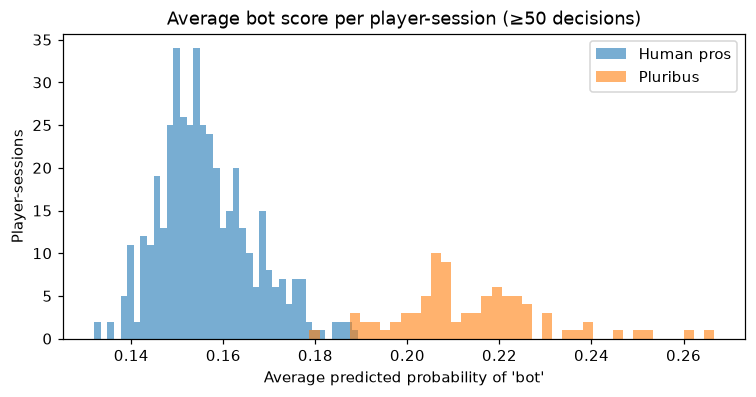

In [7]:
d["bot_score"] = scores["Gradient boosting"]
d["player_session"] = d.session + " · " + d.player
ps = d.groupby("player_session").agg(
    decisions=("bot_score", "size"),
    mean_score=("bot_score", "mean"),
    is_pluribus=("is_pluribus", "first"),
)
ps = ps[ps.decisions >= 50]
print(f"{len(ps)} player-sessions with ≥50 decisions; player-level ROC-AUC = "
      f"{roc_auc_score(ps.is_pluribus, ps.mean_score):.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
for label, g in ps.groupby("is_pluribus"):
    ax.hist(g.mean_score, bins=40, alpha=0.6, label="Pluribus" if label else "Human pros")
ax.set(title="Average bot score per player-session (≥50 decisions)",
       xlabel="Average predicted probability of 'bot'", ylabel="Player-sessions")
ax.legend()
plt.show()

Averaged over a session, the two groups barely overlap. **How many decisions does that take?** Below, each player-session is scored using only a random sample of *k* of its decisions.

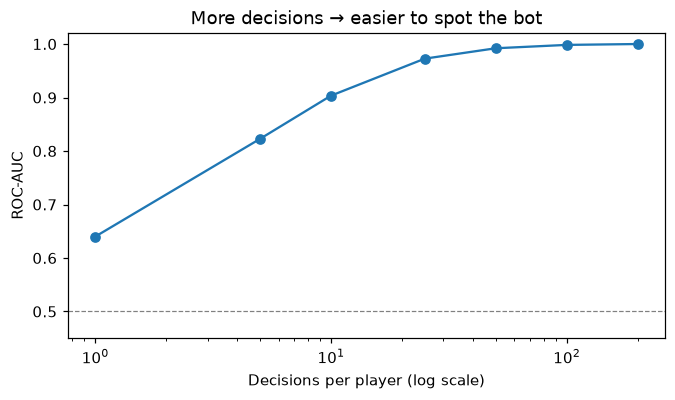

,decisions,player-sessions,ROC-AUC
0,1,552,0.640
1,5,547,0.823
2,10,546,0.903
3,25,546,0.973
4,50,518,0.992
5,100,451,0.998
6,200,163,1.000


In [8]:
rng = np.random.default_rng(RNG)
by_ps = {k: g.bot_score.to_numpy() for k, g in d.groupby("player_session")}
labels = d.groupby("player_session").is_pluribus.first()

rows = []
for k in [1, 5, 10, 25, 50, 100, 200]:
    eligible = [name for name, s in by_ps.items() if len(s) >= k]
    aucs = []
    for _ in range(20):
        means = [rng.choice(by_ps[name], k, replace=False).mean() for name in eligible]
        aucs.append(roc_auc_score(labels[eligible], means))
    rows.append({"decisions": k, "player-sessions": len(eligible), "ROC-AUC": np.mean(aucs)})
curve = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve.decisions, curve["ROC-AUC"], marker="o")
ax.axhline(0.5, color="grey", lw=0.8, ls="--")
ax.set(xscale="log", xlabel="Decisions per player (log scale)", ylabel="ROC-AUC",
       title="More decisions → easier to spot the bot", ylim=(0.45, 1.02))
plt.show()
curve.round(3)

## 5. What did the model learn?

**Permutation importance:** shuffle one feature in the test data and measure how much the score drops. A big drop means the model relies on that feature. We hold out a fifth of the sessions for this.

Held-out ROC-AUC: 0.632


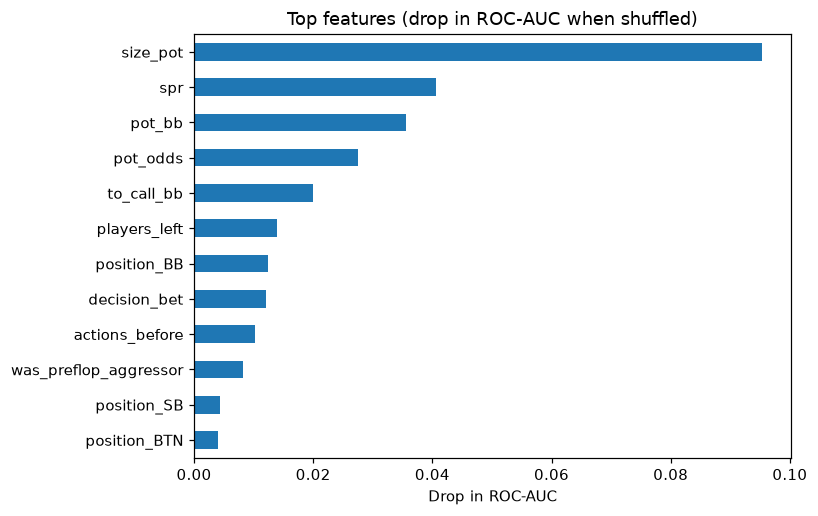

In [9]:
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RNG).split(X, y, groups))
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=RNG)
gb.fit(X.iloc[train_idx], y[train_idx])
print(f"Held-out ROC-AUC: {roc_auc_score(y[test_idx], gb.predict_proba(X.iloc[test_idx])[:, 1]):.3f}")

imp = permutation_importance(gb, X.iloc[test_idx], y[test_idx], scoring="roc_auc",
                             n_repeats=5, random_state=RNG)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
importance.tail(12).plot.barh(ax=ax)
ax.set(title="Top features (drop in ROC-AUC when shuffled)", xlabel="Drop in ROC-AUC")
plt.show()

Bet size is by far the most important feature, which matches the fixed size menu seen in section 1. So: *is the model just recognising Pluribus's bet-size menu?* That would be a fingerprint of this one bot, not of solver-like play in general. To test it, retrain with bet size rounded into coarse buckets, and with no bet size at all.

In [10]:
d["size_bucket"] = pd.cut(d.size_pot, [-1, 0, 0.3, 0.45, 0.6, 0.8, 1.05, 1.6, 100], labels=False)
no_size = [c for c in FEATURES_NUM if c != "size_pot"]
variants = {
    "All features": make_X(d),
    "Coarse bet-size buckets": make_X(d, no_size + ["size_bucket"]),
    "No bet size at all": make_X(d, no_size),
}
rows = []
for name, Xv in variants.items():
    p = cross_val_predict(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=RNG),
                          Xv, y, groups=groups, cv=cv, method="predict_proba")[:, 1]
    agg = pd.DataFrame({"p": p, "y": y, "k": d.player_session}).groupby("k").agg(
        p=("p", "mean"), y=("y", "first"), n=("p", "size"))
    agg = agg[agg.n >= 50]
    rows.append({"features": name, "decision ROC-AUC": roc_auc_score(y, p),
                 "player-session ROC-AUC": roc_auc_score(agg.y, agg.p)})
pd.DataFrame(rows).set_index("features").round(3)

,decision ROC-AUC,player-session ROC-AUC
features,,
All features,0.637,1.000
Coarse bet-size buckets,0.607,1.000
No bet size at all,0.574,0.962


Without any bet-size information the model is weaker per decision, but at the player level it still separates Pluribus from the pros very well. So the model is not only reading bet sizes: **Pluribus chooses *when* to bet, raise, call and fold differently from humans**, in ways that add up over many decisions.

## Conclusions

- **A single decision says little**, but **a player's decisions together say a lot.** Averaged over one session, the model separates Pluribus from elite pros almost perfectly.
- **The model needs combinations of features.** Logistic regression (one feature at a time) fails, while gradient boosting (combinations) works. Bot-like play is about *context*, not one stat.
- **Its standard stats look human; its bet sizes don't.** Pluribus bets from a small fixed menu of sizes, the strongest single clue.
- **It isn't only a bet-size fingerprint.** Even without bet sizes, the decision mix gives the bot away.

## Limitations to keep in mind

- **One bot, 13 humans.** The model learned "Pluribus vs these pros". Another bot, or a human using a solver in real time, may look different. And because the same 13 pros appear in every fold, part of the signal may be "not one of these 13 players".
- **Different game conditions.** Pluribus played 100-big-blind stacks reset every hand, with no rake. PokerStars games have varying stacks and rake, which changes optimal play somewhat.
- **Bet sizes may not transfer.** For PokerStars, the "no bet size" version of the model is the safer one to apply, because human players with preset bet buttons also use fixed sizes.
- **Solver-like isn't the same as cheating.** Strong regulars study solvers too. A high bot score means "plays like Pluribus", which is a reason to look closer, not proof.

## Next: notebook 03

Compute the same decision features from the PokerStars `actions` Parquet (on the machine with the data), score every decision with this model, and average per player-year. Then look at:
- which players score most bot-like, and
- who **jumps** in bot score from one year to the next (the real-time-assistance angle).